In [1]:
import pickle as pk
import numpy as np

import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder

import seaborn as sb

import sys
sys.path.append('src/')

from utils_subnets import compute_subnet_density
from utils import threshold_matrix

import random

# Panel A

In [2]:
from collections import Counter

with open('results/edge_importance_all.pck', 'rb') as f:
    edge_importance_all = pk.load(f)

#open list of regions from txt
subnet_list = []
sup_folder = '/data/shared/'
with open(sup_folder + 'HCP/100unrelated/schaefer300/Schaefer2018_300Parcels_7Networks_order.lut','r') as f:
    for line in f:
        elements = line.strip().split(' ')
        subnet_list.append(elements[4].split('_')[2])
mapping = {
    'Cont': 'C',
    'Default': 'DMN',
    'DorsAttn': 'DA',
    'Limbic': 'L',
    'SalVentAttn': 'SA',
    'SomMot': 'SM',
    'Vis': 'V'
}

subnet_list = [mapping.get(subnet, subnet) for subnet in subnet_list]

#encode subnet names as numbers
label_encoder = LabelEncoder()
subnet_num_list = label_encoder.fit_transform(subnet_list)

subnet_dict = dict(zip(label_encoder.classes_, range(0,subnet_num_list.max())))


subnet_order = np.argsort(subnet_num_list, kind='stable')

counts = Counter(subnet_num_list)
ordered_counts = dict(sorted(counts.items()))
num_roi_per_subnet = [counts[i] for i in ordered_counts.keys()]
subnet_ranges = []
start_idx = 0
for lenght in num_roi_per_subnet:
    subnet_ranges.append((start_idx, start_idx+lenght))
    start_idx += lenght

In [3]:
with open('results/edge_importance_all.pck', 'rb') as f:
    edge_importance_all = pk.load(f)

#open list of regions from txt
subnet_list = []
with open(sup_folder + 'HCP/100unrelated/schaefer300/Schaefer2018_300Parcels_7Networks_order.lut','r') as f:
    for line in f:
        elements = line.strip().split(' ')
        subnet_list.append(elements[4].split('_')[2])

#encode subnet names as numbers
label_encoder = LabelEncoder()
subnet_num_list = label_encoder.fit_transform(subnet_list)



In [4]:

#compute subnet density
edge_importance_densities = {}
perc_to_keep = 0.2

for key in edge_importance_all.keys():
    edge_importance_densities[key] = compute_subnet_density(edge_importance_all[key], subnet_list, perc_to_keep=perc_to_keep)

#double the below diagonal values to plot only the lower triangle
edge_importance_densities["differential_power_fc"][~np.eye(edge_importance_densities["differential_power_fc"].shape[0], dtype=bool)] *= 2
edge_importance_densities["differential_power_sc"][~np.eye(edge_importance_densities["differential_power_sc"].shape[0], dtype=bool)] *= 2


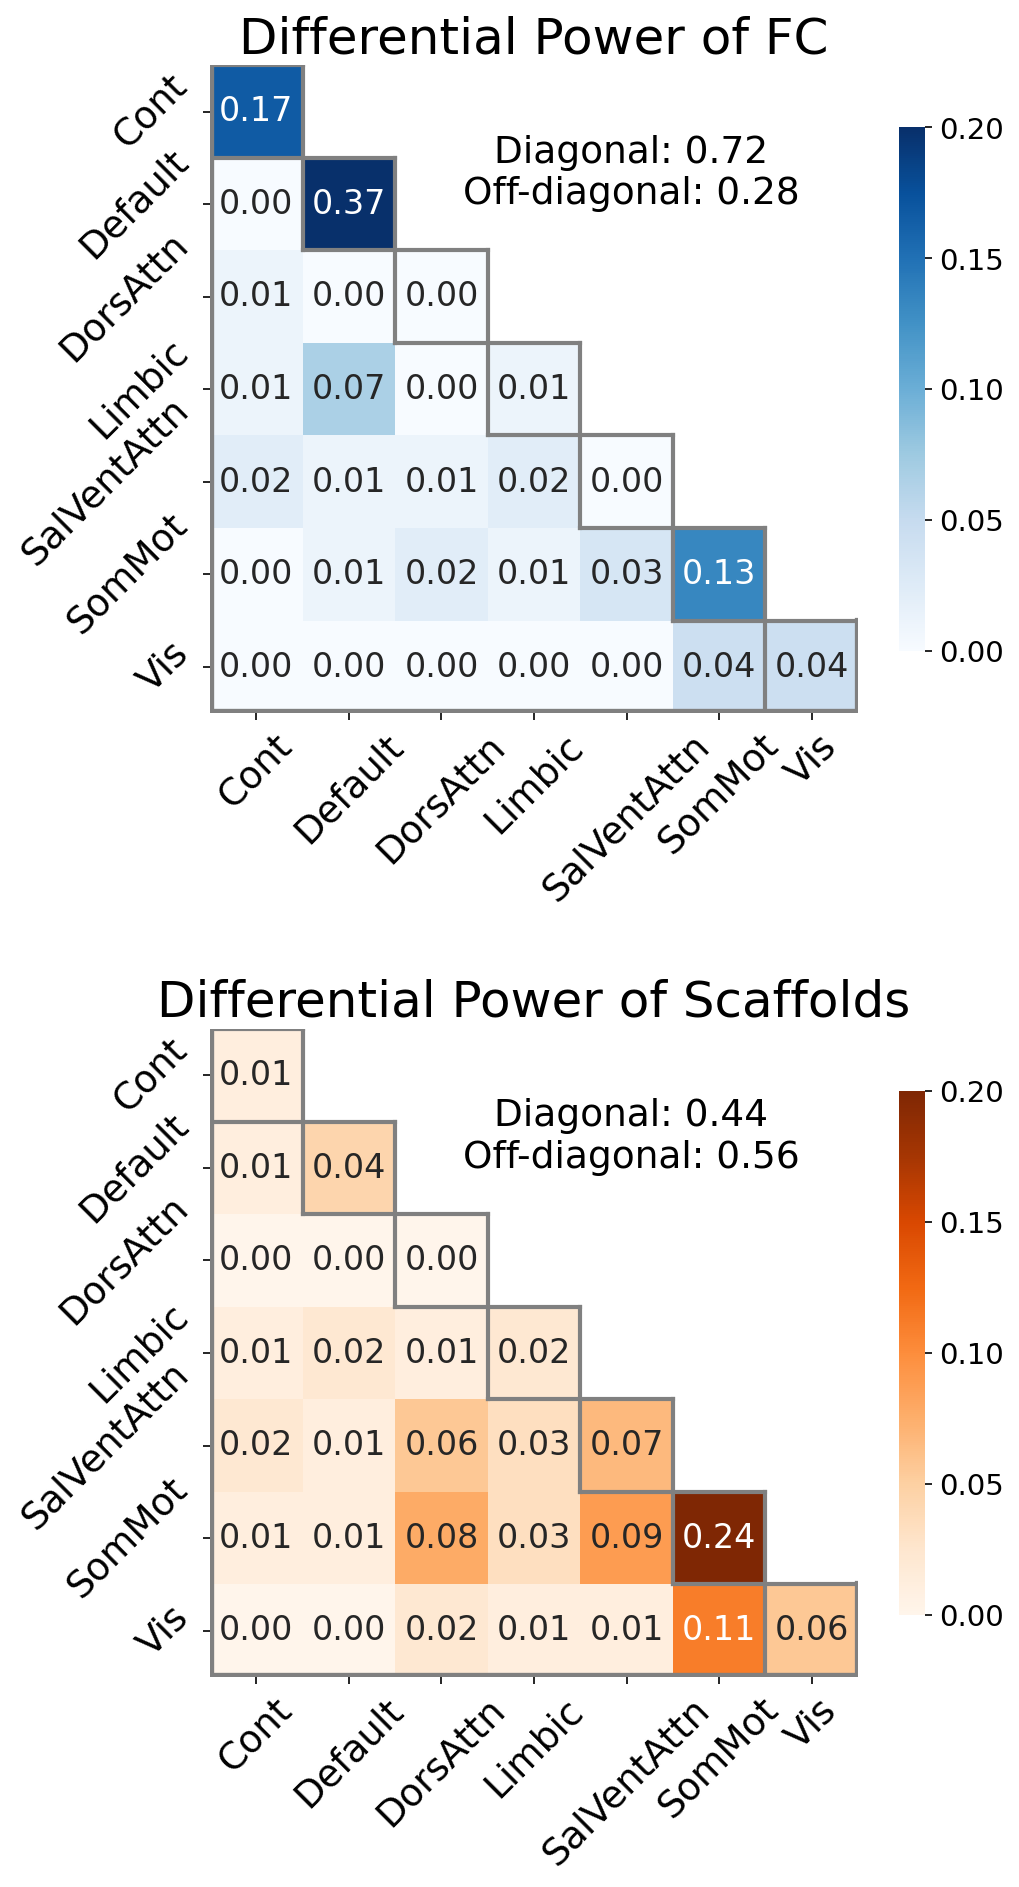

In [5]:
line_color = "gray"  # Change to desired color
vmax = 0.2


fig, axs = plt.subplots(2, 1, figsize=(7, 13), dpi=150)

sb.heatmap(
    edge_importance_densities["differential_power_fc"],
    annot=True,
    cmap="Blues",
    fmt=".2f",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_,
    mask=~np.tril(np.ones_like(edge_importance_densities["differential_power_fc"], dtype=bool)),
    cbar=True,
    cbar_kws={"shrink": .72, 'ticks': [0, 0.05, 0.1, 0.15, 0.2]},
    annot_kws={'size': 16},
    square=True,
    vmin=edge_importance_densities["differential_power_fc"].min(),
    vmax=vmax,
    ax=axs[0],
)
cbar_ax = axs[0].figure.axes[-1]
cbar_ax.tick_params(labelsize=14)

axs[0].set_xticklabels(axs[0].get_xticklabels(), rotation=45, fontsize=18)
axs[0].set_yticklabels(axs[0].get_yticklabels(), rotation=45, fontsize=18)

axs[0].axhline(7, xmin=0, xmax=7, color=line_color, linewidth=4)
axs[0].axhline(1, xmin=0, xmax=2/7, color=line_color, linewidth=2)
axs[0].axhline(2, xmin=1/7, xmax=3/7, color=line_color, linewidth=2)
axs[0].axhline(3, xmin=2/7, xmax=4/7, color=line_color, linewidth=2)
axs[0].axhline(4, xmin=3/7, xmax=5/7, color=line_color, linewidth=2)
axs[0].axhline(5, xmin=4/7, xmax=6/7, color=line_color, linewidth=2)
axs[0].axhline(6, xmin=5/7, xmax=7, color=line_color, linewidth=2)
axs[0].axhline(0, xmin=0, xmax=1/7, color=line_color, linewidth=2)

axs[0].axvline(0, ymin=0, ymax=7, color=line_color, linewidth=4)
axs[0].axvline(6, ymin=0, ymax=2/7, color=line_color, linewidth=2)
axs[0].axvline(5, ymin=1/7, ymax=3/7, color=line_color, linewidth=2)
axs[0].axvline(4, ymin=2/7, ymax=4/7, color=line_color, linewidth=2)
axs[0].axvline(3, ymin=3/7, ymax=5/7, color=line_color, linewidth=2)
axs[0].axvline(2, ymin=4/7, ymax=6/7, color=line_color, linewidth=2)
axs[0].axvline(1, ymin=5/7, ymax=7, color=line_color, linewidth=2)
axs[0].axvline(7, ymin=0, ymax=1/7, color=line_color, linewidth=3)

axs[0].set_title('Differential Power of FC', fontsize=24)

sb.heatmap(
    edge_importance_densities["differential_power_sc"],
    annot=True,
    cmap="Oranges",
    fmt=".2f",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_,
    mask=~np.tril(np.ones_like(edge_importance_densities["differential_power_sc"], dtype=bool)),
    cbar=True,
    cbar_kws={"shrink": .72, 'ticks': [0, 0.05, 0.1, 0.15, 0.2]},
    annot_kws={'size': 16},
    square=True,
    vmin=edge_importance_densities["differential_power_fc"].min(),
    vmax=vmax,
    ax=axs[1]
)

cbar_ax = axs[1].figure.axes[-1]
cbar_ax.tick_params(labelsize=14)

axs[1].set_xticklabels(axs[1].get_xticklabels(), rotation=45, fontsize=18)
axs[1].set_yticklabels(axs[1].get_yticklabels(), rotation=45, fontsize=18)

axs[1].axhline(7, xmin=0, xmax=7, color=line_color, linewidth=4)
axs[1].axhline(1, xmin=0, xmax=2/7, color=line_color, linewidth=2)
axs[1].axhline(2, xmin=1/7, xmax=3/7, color=line_color, linewidth=2)
axs[1].axhline(3, xmin=2/7, xmax=4/7, color=line_color, linewidth=2)
axs[1].axhline(4, xmin=3/7, xmax=5/7, color=line_color, linewidth=2)
axs[1].axhline(5, xmin=4/7, xmax=6/7, color=line_color, linewidth=2)
axs[1].axhline(6, xmin=5/7, xmax=7, color=line_color, linewidth=2)
axs[1].axhline(0, xmin=0, xmax=1/7, color=line_color, linewidth=2)

axs[1].axvline(0, ymin=0, ymax=7, color=line_color, linewidth=4)
axs[1].axvline(6, ymin=0, ymax=2/7, color=line_color, linewidth=2)
axs[1].axvline(5, ymin=1/7, ymax=3/7, color=line_color, linewidth=2)
axs[1].axvline(4, ymin=2/7, ymax=4/7, color=line_color, linewidth=2)
axs[1].axvline(3, ymin=3/7, ymax=5/7, color=line_color, linewidth=2)
axs[1].axvline(2, ymin=4/7, ymax=6/7, color=line_color, linewidth=2)
axs[1].axvline(1, ymin=5/7, ymax=7, color=line_color, linewidth=2)
axs[1].axvline(7, ymin=0, ymax=1/7, color=line_color, linewidth=3)

axs[1].set_title('Differential Power of Scaffolds', fontsize=24)


# Calculate sums for "differential_power_fc"
fc_diag = np.diag(edge_importance_densities["differential_power_fc"]).sum()
fc_off = (edge_importance_densities["differential_power_fc"].sum() - fc_diag) / 2
axs[0].text(
    0.65,
    5.5 / 7,
    f"Diagonal: {fc_diag:.2f}\nOff-diagonal: {fc_off:.2f}",
    ha="center",
    transform=axs[0].transAxes,
    fontsize=18
)

# Calculate sums for "differential_power_sc"
sc_diag = np.diag(edge_importance_densities["differential_power_sc"]).sum()
sc_off = (edge_importance_densities["differential_power_sc"].sum() - sc_diag) / 2
axs[1].text(
    0.65,
    5.5 / 7,
    f"Diagonal: {sc_diag:.2f}\nOff-diagonal: {sc_off:.2f}",
    ha="center",
    transform=axs[1].transAxes,
    fontsize=18
)

plt.tight_layout()
#plt.savefig('../figures/final/fig3/fig3A.png', dpi=300, bbox_inches='tight')
plt.show()


# Panel B

In [9]:
from collections import Counter

with open('results/edge_importance_all.pck', 'rb') as f:
    edge_importance_all = pk.load(f)

#open list of regions from txt
subnet_list = []
with open(sup_folder+'HCP/100unrelated/schaefer300/Schaefer2018_300Parcels_7Networks_order.lut','r') as f:
    for line in f:
        elements = line.strip().split(' ')
        subnet_list.append(elements[4].split('_')[2])
mapping = {
    'Cont': 'C',
    'Default': 'DMN',
    'DorsAttn': 'DA',
    'Limbic': 'L',
    'SalVentAttn': 'SA',
    'SomMot': 'SM',
    'Vis': 'V'
}

subnet_list = [mapping.get(subnet, subnet) for subnet in subnet_list]

#encode subnet names as numbers
label_encoder = LabelEncoder()
subnet_num_list = label_encoder.fit_transform(subnet_list)

subnet_dict = dict(zip(label_encoder.classes_, range(0,subnet_num_list.max())))


subnet_order = np.argsort(subnet_num_list, kind='stable')

counts = Counter(subnet_num_list)
ordered_counts = dict(sorted(counts.items()))
num_roi_per_subnet = [counts[i] for i in ordered_counts.keys()]
subnet_ranges = []
start_idx = 0
for lenght in num_roi_per_subnet:
    subnet_ranges.append((start_idx, start_idx+lenght))
    start_idx += lenght

In [10]:
#compute subnet density
edge_importance_densities = {}

for key in edge_importance_all.keys():
    edge_importance_densities[key] = compute_subnet_density(edge_importance_all[key], subnet_list)


edge_importance_all_thresholded = {}
for key in edge_importance_all.keys():
    edge_importance_all_thresholded[key] = threshold_matrix(edge_importance_all[key], perc_to_keep=perc_to_keep)

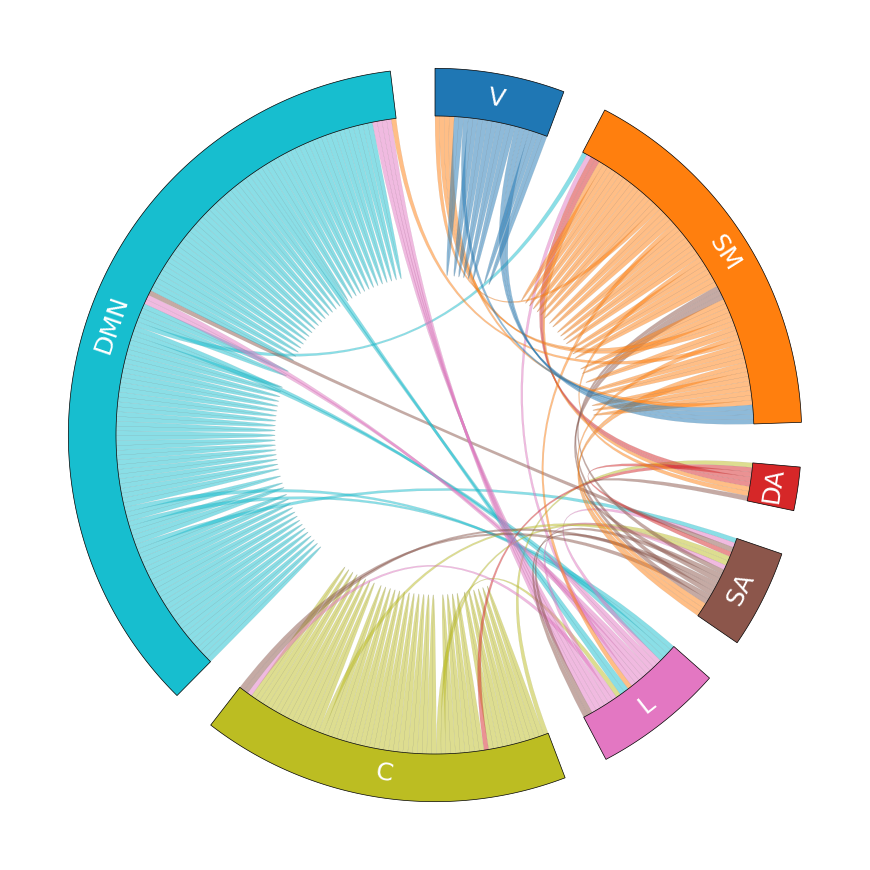

In [13]:
from pycirclize import Circos
import pandas as pd

row_names = subnet_list
col_names = row_names

#edge_importance_all_thresholded['differential_power_fc'][np.diag_indices_from(edge_importance_all_thresholded['differential_power_fc'])] = 0
matrix_df = pd.DataFrame(edge_importance_all_thresholded['differential_power_fc'], index=row_names, columns=col_names)

# Initialize Circos instance for chord diagram plot
circos = Circos.chord_diagram(
    matrix_df,
    space=7,
    r_lim=(87, 100),
    cmap="tab10",
    #ticks_interval=500,
    label_kws=dict(r=90, size=18, color="white")
)

#print(matrix_df)
fig = circos.plotfig()

#plt.savefig('../figures/final/fig3/fig3B1.png', dpi=300, bbox_inches='tight')
plt.show()

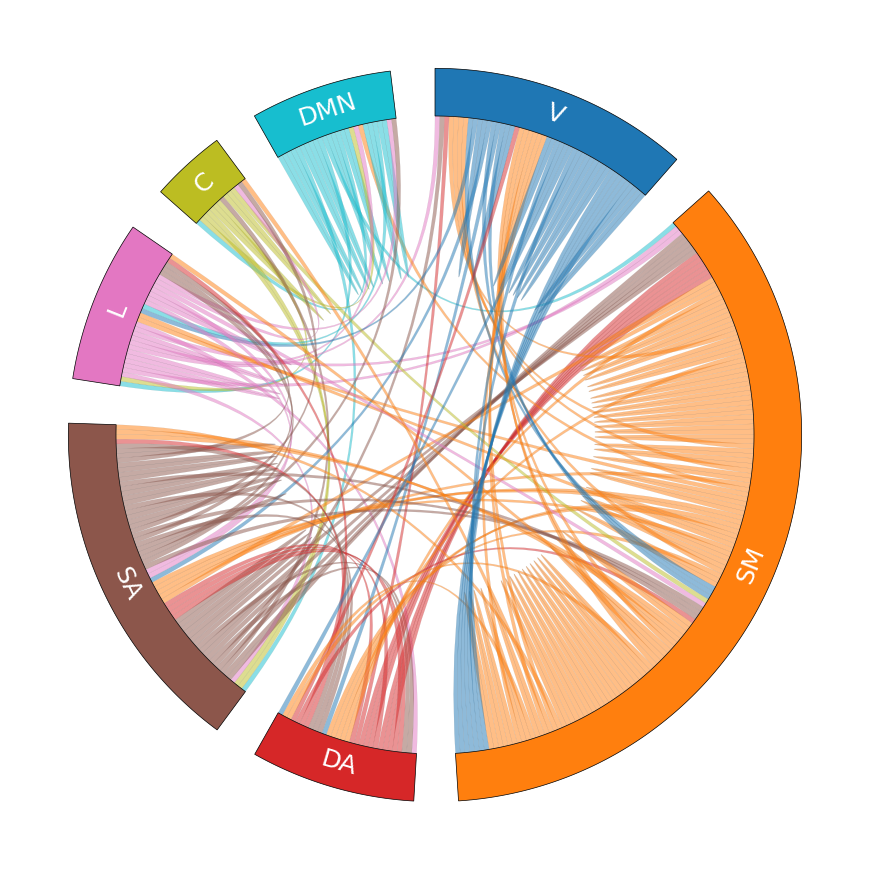

In [14]:
from pycirclize import Circos
import pandas as pd

row_names = subnet_list
col_names = row_names

matrix_df = pd.DataFrame(edge_importance_all_thresholded['differential_power_sc'], index=row_names, columns=col_names)

# Initialize Circos instance for chord diagram plot
circos = Circos.chord_diagram(
    matrix_df,
    space=7,
    r_lim=(87, 100),
    cmap="tab10",
    #ticks_interval=500,
    label_kws=dict(r=90, size=18, color="white"),
)

#print(matrix_df)
fig = circos.plotfig()

#plt.savefig('../figures/final/fig3/fig3B2.png', dpi=300, bbox_inches='tight')
plt.show()

## Panel C

In [15]:
from hcp_IO import load_scaffold_schaefer300
from utils import apply_threshold_to_nested_dict


#load fc and sc as 2 levels dictionary with keys subjects and sessions

data_dir = sup_folder + 'HCP/100unrelated/schaefer300/no_hp/'
scaffold_dir = 'scaffolds/whole/'
fc_dir = 'fc/whole/'

sc = load_scaffold_schaefer300(data_dir+scaffold_dir+'/freq/')
with open(data_dir+'fc/whole/whole_corrs.pck', 'rb') as f:
    fc = pk.load(f)
fc_th = apply_threshold_to_nested_dict(fc,1)

In [16]:
#open list of regions from txt
#regions_list = []
#with open('../data/schaefer300_selected/Schaefer2018_300Parcels_7Networks_order.lut','r') as f:
    # for line in f:
    #     elements = line.strip().split(' ')
    #     regions_list.append(elements[4])

#list of regions names        
#regions7 = [reg.split('_')[2] for reg in subnet_list]
regions7 = subnet_list

label_encoder = LabelEncoder()

#list of regions encoded as numbers
regions7_numbers = label_encoder.fit_transform(regions7)
#dictionary with regions names and their corresponding numbers
dict_regions7 = dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_)))


In [17]:
from utils_subnets import extract_subregion

dict_regions7 = dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_)))


#separate the SC dictionary into subnets
sc_subnet = {}

for i, name in enumerate(dict_regions7.keys()):
    sc_subnet[name] = {}
    for subject in sc.keys():
        sc_subnet[name][subject] = {}
        for sess in [0,1]:
            sc_subnet[name][subject][sess] = extract_subregion(sc[subject][sess], regions7_numbers, i)
            
#separate the FC dictionary into subnets
fc_subnet = {}

for i, name in enumerate(dict_regions7.keys()):
    fc_subnet[name] = {}
    for subject in fc.keys():
        fc_subnet[name][subject] = {}
        for sess in [0,1]:
            fc_subnet[name][subject][sess] = extract_subregion(fc[subject][sess], regions7_numbers, i)

In [18]:
## Extract an array of $BOOT_iterations with $Nsubjects_boot subjects randomly sampled from a total of 50
## This is for running the brain fingerprinting analysis
BOOT_iterations=100
Nsubjects_boot=80
all_sample_subjs=np.array([sorted(random.sample(list(sc_subnet['C'].keys()),Nsubjects_boot)) for i in range(BOOT_iterations)])

In [19]:
from tqdm.notebook import tqdm

from fingerprinting import compute_success_rate

In [20]:
labels = list(dict_regions7.keys())

dict_val_networks_fc = {i:[] for i in labels}
dict_val_networks_sc = {i:[] for i in labels}

#Loop over the bootstrapped samples
for id_sample in tqdm(all_sample_subjs):
    #Loop throught the networks
    for i, name in enumerate(dict_regions7.keys()):
        #Extract the SC and FC data for the current network
        sc_data_0 = np.array([sc_subnet[name][subject][0].flatten() for subject in id_sample])
        sc_data_1 = np.array([sc_subnet[name][subject][1].flatten() for subject in id_sample])
        fc_data_0 = np.array([fc_subnet[name][subject][0].flatten() for subject in id_sample])
        fc_data_1 = np.array([fc_subnet[name][subject][1].flatten() for subject in id_sample])

        #correlation matrix
        sc_corr = np.corrcoef(sc_data_0, sc_data_1)[Nsubjects_boot:, :Nsubjects_boot]
        fc_corr = np.corrcoef(fc_data_0, fc_data_1)[Nsubjects_boot:, :Nsubjects_boot]

        id_rate_sc = np.array(compute_success_rate(sc_corr))
        id_rate_fc = np.array(compute_success_rate(fc_corr))

        dict_val_networks_fc[name].append(id_rate_fc.mean())
        dict_val_networks_sc[name].append(id_rate_sc.mean())

  0%|          | 0/100 [00:00<?, ?it/s]

/home/spoetto/miniconda3/envs/tda/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3065: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/home/spoetto/miniconda3/envs/tda/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3066: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


In [22]:
#load fc and sc as 2 levels dictionary with keys subjects and sessions

data_dir = sup_folder + '/HCP/100unrelated/schaefer300/no_hp/'
scaffold_dir = 'scaffolds/whole/'
fc_dir = 'fc/whole/'

sc = load_scaffold_schaefer300(data_dir+scaffold_dir+'/freq/')
with open(data_dir+'fc/whole/whole_corrs.pck', 'rb') as f:
    fc = pk.load(f)
fc_th = apply_threshold_to_nested_dict(fc,1)

In [23]:
def remove_subnetworks(d, list_of_regions):
    """
    Remove subnetworks based on a list of regions for every square matrix within a nested dictionary.

    Args:
        d (dict): The nested dictionary containing square matrices.
        list_of_regions (list): The list of regions to remove from the square matrices.
        
    Returns:
        dict: The modified nested dictionary with the specified regions removed from the square matrices.
    """
    for key, value in d.items():
        if isinstance(value, dict):
            # Recursively process nested dictionaries
            d[key] = remove_subnetworks(value, list_of_regions)
        elif isinstance(value, np.ndarray) and value.shape[0] == value.shape[1]:
            # Remove the specified regions from the square matrix
            set_to_zero = tuple(np.transpose(list(itertools.product(list_of_regions, list_of_regions))))
            d[key][set_to_zero] = 0
    return d

In [24]:
import copy
import itertools
sc_no_subnets = copy.deepcopy(sc)
fc_no_subnets = copy.deepcopy(fc)
fc_th_no_subnets = copy.deepcopy(fc_th)


# Remove the subnetworks from the SC and FC matrices
for n in range(regions7_numbers.max()+1):
    list_of_regions = np.where(regions7_numbers == n)[0]
    sc_no_subnets = remove_subnetworks(sc_no_subnets, list_of_regions)
    fc_no_subnets = remove_subnetworks(fc_no_subnets, list_of_regions)
    fc_th_no_subnets = remove_subnetworks(fc_th_no_subnets, list_of_regions)

In [25]:
#Loop over the bootstrapped samples
dict_val_networks_fc['No subnet'] = []
dict_val_networks_sc['No subnet'] = []
for id_sample in tqdm(all_sample_subjs):
    #Extract the SC and FC data for the current network
    sc_data_0 = np.array([sc_no_subnets[subject][0].flatten() for subject in id_sample])
    sc_data_1 = np.array([sc_no_subnets[subject][1].flatten() for subject in id_sample])
    fc_data_0 = np.array([fc_th_no_subnets[subject][0].flatten() for subject in id_sample])
    fc_data_1 = np.array([fc_th_no_subnets[subject][1].flatten() for subject in id_sample])

    #correlation matrix
    sc_corr = np.corrcoef(sc_data_0, sc_data_1)[Nsubjects_boot:, :Nsubjects_boot]
    fc_corr = np.corrcoef(fc_data_0, fc_data_1)[Nsubjects_boot:, :Nsubjects_boot]

    id_rate_sc = np.array(compute_success_rate(sc_corr))
    id_rate_fc = np.array(compute_success_rate(fc_corr))

    dict_val_networks_fc['No subnet'].append(id_rate_fc.mean())
    dict_val_networks_sc['No subnet'].append(id_rate_sc.mean())

  0%|          | 0/100 [00:00<?, ?it/s]

In [26]:
#Loop over the bootstrapped samples for full matrices
dict_val_networks_fc['Full matrix'] = []
dict_val_networks_sc['Full matrix'] = []
for id_sample in tqdm(all_sample_subjs):
    #Extract the SC and FC data for the full matrices
    sc_data_0 = np.array([sc[subject][0].flatten() for subject in id_sample])
    sc_data_1 = np.array([sc[subject][1].flatten() for subject in id_sample])
    fc_data_0 = np.array([fc_th[subject][0].flatten() for subject in id_sample])
    fc_data_1 = np.array([fc_th[subject][1].flatten() for subject in id_sample])

    #correlation matrix
    sc_corr = np.corrcoef(sc_data_0, sc_data_1)[Nsubjects_boot:, :Nsubjects_boot]
    fc_corr = np.corrcoef(fc_data_0, fc_data_1)[Nsubjects_boot:, :Nsubjects_boot]

    id_rate_sc = np.array(compute_success_rate(sc_corr))
    id_rate_fc = np.array(compute_success_rate(fc_corr))

    dict_val_networks_fc['Full matrix'].append(id_rate_fc.mean())
    dict_val_networks_sc['Full matrix'].append(id_rate_sc.mean())

  0%|          | 0/100 [00:00<?, ?it/s]

In [27]:
pd_subnet_idrate_fc = pd.DataFrame(dict_val_networks_fc)
pd_subnet_idrate_sc = pd.DataFrame(dict_val_networks_sc)

# Create desired order with Full matrix at the end
desired_order_temp = list(pd_subnet_idrate_sc.drop(columns=['Full matrix']).median().sort_values().index)
desired_order = desired_order_temp + ['Full matrix']

pd_subnet_idrate_fc = pd_subnet_idrate_fc[desired_order]
pd_subnet_idrate_sc = pd_subnet_idrate_sc[desired_order]

pd_subnet_idrate_sc['Full matrix']


0     100.0
1     100.0
2     100.0
3     100.0
4     100.0
      ...  
95    100.0
96    100.0
97    100.0
98    100.0
99    100.0
Name: Full matrix, Length: 100, dtype: float64

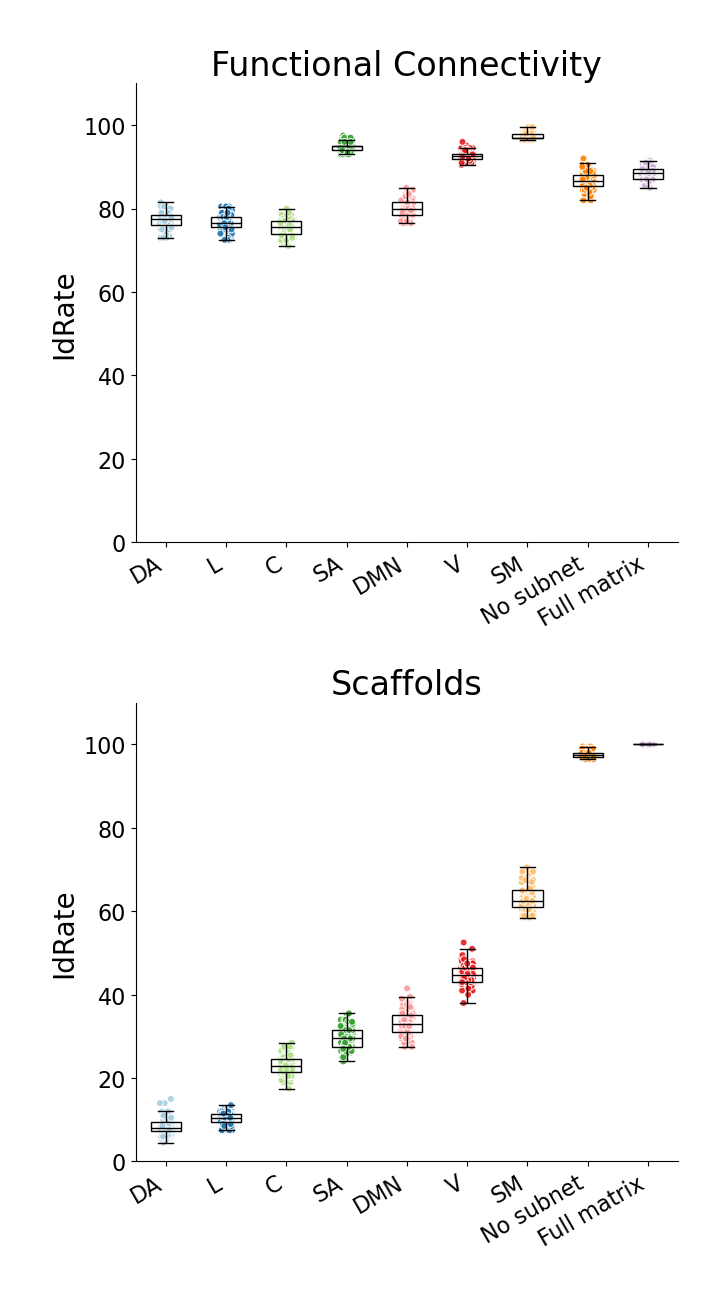

In [30]:
PROPS = {
    'boxprops':{'facecolor':'none', 'edgecolor':'black'},
    'medianprops':{'color':'black'},
    'whiskerprops':{'color':'black'},
    'capprops':{'color':'black'}
}
fig = plt.figure(figsize=(7,14))

# Subplot 1 -> FC, Subplot 2 -> SC
for subplotID, (df_toplot, ylabel) in enumerate(zip([pd_subnet_idrate_fc, pd_subnet_idrate_sc],
                                                    [r'Functional Connectivity', r"Scaffolds"])):
    ax = plt.subplot(2, 1, subplotID+1)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # Extended color palette to accommodate the additional boxplot
    n_colors = len(df_toplot.columns)
    colors = sb.color_palette("Paired", n_colors=24)[12:12+n_colors]
    
    sb.boxplot(df_toplot, palette=colors,
               showfliers=False, width=0.5, **PROPS)
    sb.stripplot(df_toplot, alpha=0.9, jitter=True,
                 palette=colors,
                 edgecolor='w', size=5, linewidth=0.75, zorder=-1)
    plt.xticks(rotation=30, fontsize=16, ha='right')
    plt.yticks(fontsize=16)
    ax.title.set_text(ylabel)
    ax.title.set_fontsize(24)
    ax.set_ylim(0, 110)
    plt.ylabel('IdRate', fontsize=20)
plt.subplots_adjust(hspace=0.35)
#plt.tight_layout()
#plt.savefig('../figures/final/fig3/fig3C.png', dpi=300)
plt.show()